# Demand Forecasting per Produk MyVentory (Harian)

Prediksi **jumlah unit terjual setiap produk** per **hari** memakai tiga model:

| Model | Jenis | Keterangan |
|---|---|---|
| SARIMA | statistik | order dicari dengan grid AIC, musiman mingguan 7 hari |
| ETS (Holt-Winters) | statistik | tren aditif damping + musiman mingguan |
| Gradient Boosting | machine learning | fitur lag harian + kalender |

Pembanding: **baseline seasonal-naive** (nilai 7 hari sebelumnya).

- Sumber data: `data/Transactions.csv` (transaksi 3 outlet, Januari - September 2025)
- Target: jumlah unit per produk dijumlahkan per hari
- Data uji: 28 hari terakhir
- Model tersimpan meramal **1 minggu (7 hari)** ke depan
- Semua hasil (model, metadata, CSV, grafik) disimpan di folder yang sama: `artifacts/demand_forecast_product/`

## 1. Konfigurasi

Seluruh pengaturan ada di satu tempat, termasuk satu folder keluaran untuk model, metadata, CSV, dan grafik.

In [1]:
import json
import pickle
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")

DATA_PATH = Path("..") / "data" / "Transactions.csv"
OUTPUT_DIR = Path("..") / "artifacts" / "demand_forecast_product"
MODEL_PATH = OUTPUT_DIR / "model.pkl"
METADATA_PATH = OUTPUT_DIR / "metadata.json"

TEST_DAYS = 28      # hari terakhir sebagai data uji
SEASON_LENGTH = 7   # pola mingguan
HORIZON_DAYS = 7    # model disimpan meramal 1 minggu ke depan
SEED = 42

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

print("pandas      :", pd.__version__)
print("folder hasil:", OUTPUT_DIR.resolve())

C:\Users\Radit\anaconda3\Lib\site-packages\pandas\core\computation\expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
C:\Users\Radit\anaconda3\Lib\site-packages\pandas\core\arrays\masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.7' currently installed).
  from pandas.core import (


pandas      : 3.0.3
folder hasil: C:\Users\Radit\Politeknik Negeri Malang\Semester 5\ProjectBasedLearning_MyVentory\ML\artifacts\demand_forecast_product


## 2. Memuat dan mengagregasi data

Satu baris transaksi = satu struk, dan kolom `Items` bisa memuat beberapa produk sekaligus.
Daftar item dipecah menjadi satu baris per produk, lalu dihitung jumlah unitnya per tanggal
sehingga terbentuk matriks harian berukuran hari x produk.

In [2]:
transactions = pd.read_csv(DATA_PATH, parse_dates=["Date"])

items = transactions.assign(Item=transactions.Items.str.split(", ")).explode("Item")
items["Item"] = items.Item.str.strip()

daily = items.groupby(["Date", "Item"]).size().unstack(fill_value=0).asfreq("D").fillna(0).astype(int)

assert daily.notna().all().all(), "ada tanggal tanpa transaksi"
assert not daily.index.duplicated().any(), "ada tanggal duplikat"

print(f"baris transaksi : {len(transactions):,}")
print(f"outlet          : {sorted(transactions.Outlet.unique())}")
print(f"rentang tanggal : {daily.index.min().date()} s/d {daily.index.max().date()}")
print(f"jumlah hari     : {len(daily)}")
print(f"jumlah produk   : {daily.shape[1]}")
print()
print("total unit per bulan:")
print(daily.resample("MS").sum().sum(axis=1).to_string())

baris transaksi : 53,820
outlet          : ['SHOP001', 'SHOP002', 'SHOP003']
rentang tanggal : 2025-01-02 s/d 2025-09-30
jumlah hari     : 272
jumlah produk   : 94

total unit per bulan:
Date
2025-01-01    6191
2025-02-01    7059
2025-03-01    7165
2025-04-01    5165
2025-05-01    6241
2025-06-01    8649
2025-07-01    8286
2025-08-01    6857
2025-09-01    6360
Freq: MS


## 3. Eksplorasi awal

Melihat skala nilai, pola hari kerja, dan kekuatan pola mingguan.

In [3]:
daily_total = daily.sum(axis=1)

print("Statistik harian permintaan seluruh produk (unit):")
print(daily_total.describe().round(2).to_string())
print()
print("Rata-rata per hari dalam minggu (unit):")
dow_mean = daily_total.groupby(daily.index.dayofweek).mean()
dow_mean.index = ["Senin", "Selasa", "Rabu", "Kamis", "Jumat", "Sabtu", "Minggu"]
print(dow_mean.round(2).to_string())

Statistik harian permintaan seluruh produk (unit):
count    272.00
mean     227.84
std       38.01
min      147.00
25%      201.75
50%      224.00
75%      254.00
max      323.00

Rata-rata per hari dalam minggu (unit):
Senin     226.49
Selasa    227.95
Rabu      228.55
Kamis     227.31
Jumat     230.08
Sabtu     223.18
Minggu    231.36


In [4]:
from statsmodels.tsa.seasonal import STL

stl = STL(daily_total, period=SEASON_LENGTH, robust=True).fit()
strength = max(0.0, 1 - stl.resid.var() / daily_total.var())

print(f"kekuatan pola mingguan (0 sampai 1): {strength:.3f}")
print("nilai di atas 0.5 berarti pola mingguan jelas dan layak dimodelkan.")

kekuatan pola mingguan (0 sampai 1): 0.796
nilai di atas 0.5 berarti pola mingguan jelas dan layak dimodelkan.


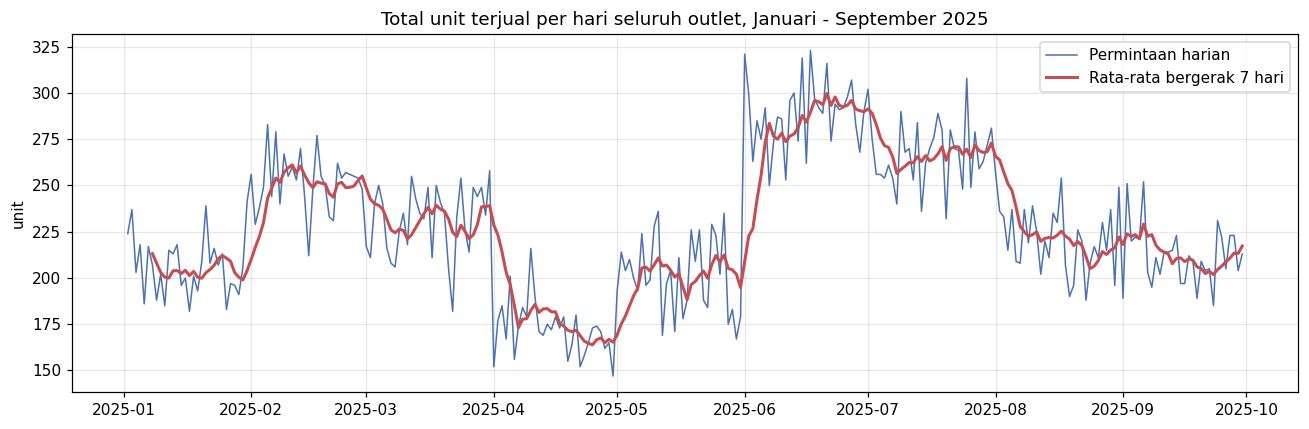

In [5]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(daily_total.index, daily_total.values, lw=1, color="#4c72b0", label="Permintaan harian")
ax.plot(daily_total.index, daily_total.rolling(7).mean(), lw=2, color="#c44e52", label="Rata-rata bergerak 7 hari")
ax.set_title("Total unit terjual per hari seluruh outlet, Januari - September 2025")
ax.set_ylabel("unit")
ax.legend()
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "fig_1_series.png", dpi=120)
plt.show()

## 4. Membagi data latih dan data uji

28 hari terakhir dipakai sebagai data uji, 244 hari sebelumnya sebagai data latih.
Baseline seasonal-naive menjadi acuan minimal yang harus dikalahkan model.

In [6]:
train = daily.iloc[:-TEST_DAYS]
test = daily.iloc[-TEST_DAYS:]

y_train = train.to_numpy(dtype=float)
y_test = test.to_numpy(dtype=float)

# baseline seasonal-naive per produk: ulangi pola 7 hari terakhir data latih
forecast_baseline = np.tile(train.iloc[-SEASON_LENGTH:].to_numpy(dtype=float), (TEST_DAYS // SEASON_LENGTH, 1))

print(f"data latih : {train.index.min().date()} s/d {train.index.max().date()} ({len(train)} hari)")
print(f"data uji   : {test.index.min().date()} s/d {test.index.max().date()} ({len(test)} hari)")
print(f"produk     : {daily.shape[1]}")
print(f"rata-rata data latih : {y_train.mean():,.2f} unit per produk per hari")
print(f"rata-rata data uji   : {y_test.mean():,.2f} unit per produk per hari")

data latih : 2025-01-02 s/d 2025-09-02 (244 hari)
data uji   : 2025-09-03 s/d 2025-09-30 (28 hari)
produk     : 94
rata-rata data latih : 2.44 unit per produk per hari
rata-rata data uji   : 2.25 unit per produk per hari


## 5. Model 1 - SARIMA

Pencarian grid kecil berdasarkan AIC dilakukan untuk **setiap produk**. Komponen musiman memakai
periode 7 (mingguan). Kombinasi yang gagal konvergen dilewati.

In [7]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

grid_result = []
for product in daily.columns:
    y = train[product].to_numpy(dtype=float)
    for p in range(3):
        for q in range(3):
            for P in range(2):
                for Q in range(2):
                    try:
                        candidate = SARIMAX(
                            y,
                            order=(p, 1, q),
                            seasonal_order=(P, 1, Q, SEASON_LENGTH),
                            enforce_stationarity=False,
                            enforce_invertibility=False,
                        ).fit(disp=False)
                        if np.isfinite(candidate.aic):
                            grid_result.append({"product": product, "p": p, "d": 1, "q": q, "P": P, "D": 1, "Q": Q, "AIC": candidate.aic})
                    except Exception:
                        pass

grid_table = pd.DataFrame(grid_result).sort_values(["product", "AIC"]).reset_index(drop=True)
print(f"kombinasi berhasil diuji: {len(grid_table)} dari {36 * daily.shape[1]}")
print()
print(f"lima order terbaik untuk produk {daily.columns[0]}:")
print(grid_table[grid_table["product"] == daily.columns[0]].head(5).round(1).to_string(index=False))

C:\Users\Radit\anaconda3\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


C:\Users\Radit\anaconda3\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


C:\Users\Radit\anaconda3\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


C:\Users\Radit\anaconda3\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


C:\Users\Radit\anaconda3\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


C:\Users\Radit\anaconda3\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


... (92 outputs left out)

C:\Users\Radit\anaconda3\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


C:\Users\Radit\anaconda3\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


C:\Users\Radit\anaconda3\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


kombinasi berhasil diuji: 3384 dari 3384

lima order terbaik untuk produk Air Mineral:
    product  p  d  q  P  D  Q   AIC
Air Mineral  1  1  2  0  1  1 892.7
Air Mineral  0  1  2  0  1  1 892.8
Air Mineral  2  1  2  0  1  1 894.5
Air Mineral  1  1  2  1  1  1 896.8
Air Mineral  0  1  2  1  1  1 896.9


In [8]:
best_orders = grid_table.groupby("product", sort=False).head(1).set_index("product")

sarima = {}
forecast_sarima = {}
for product in daily.columns:
    first = best_orders.loc[product]
    best_p, best_q = int(first.p), int(first.q)
    best_P, best_Q = int(first.P), int(first.Q)
    sarima[product] = SARIMAX(
        train[product].to_numpy(dtype=float),
        order=(best_p, 1, best_q),
        seasonal_order=(best_P, 1, best_Q, SEASON_LENGTH),
        enforce_stationarity=False,
        enforce_invertibility=False,
    ).fit(disp=False)
    forecast_sarima[product] = np.clip(np.asarray(sarima[product].forecast(TEST_DAYS), dtype=float), 0, None)

forecast_sarima = pd.DataFrame(forecast_sarima)
print("order terpilih (lima produk pertama):")
print(best_orders[["p", "q", "P", "Q", "AIC"]].head(5).round(1).to_string())
print()
print("tujuh prediksi pertama (unit, lima produk pertama):")
print(forecast_sarima.iloc[:7, :5].round(2).to_string())

C:\Users\Radit\anaconda3\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


C:\Users\Radit\anaconda3\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


order terpilih (lima produk pertama):
                            p  q  P  Q    AIC
product                                      
Air Mineral                 1  2  0  1  892.7
Americano (Hot Arabica)     0  2  0  1  928.2
Americano (Hot Houseblend)  0  2  0  1  881.5
Americano (Ice Arabica)     0  2  0  1  873.1
Americano (Ice Houesblend)  0  2  0  1  914.1

tujuh prediksi pertama (unit, lima produk pertama):
   Air Mineral  Americano (Hot Arabica)  Americano (Hot Houseblend)  Americano (Ice Arabica)  Americano (Ice Houesblend)
0         2.13                     1.54                        2.38                     1.96                        2.17
1         2.48                     1.64                        2.58                     1.84                        2.03
2         2.41                     1.76                        2.82                     2.43                        2.29
3         1.87                     1.53                        2.98                     2.33           

## 6. Model 2 - ETS (Holt-Winters)

Tren aditif dengan damping dan komponen musiman mingguan. Parameter smoothing diestimasi otomatis
untuk setiap produk.

In [9]:
from statsmodels.tsa.exponential_smoothing.ets import ETSModel

ets = {}
forecast_ets = {}
for product in daily.columns:
    ets[product] = ETSModel(
        train[product].to_numpy(dtype=float),
        error="add",
        trend="add",
        damped_trend=True,
        seasonal="add",
        seasonal_periods=SEASON_LENGTH,
    ).fit(disp=False)
    forecast_ets[product] = np.clip(np.asarray(ets[product].forecast(TEST_DAYS), dtype=float), 0, None)

forecast_ets = pd.DataFrame(forecast_ets)

smoothing = dict(zip(ets[daily.columns[0]].param_names, ets[daily.columns[0]].params))
print(f"parameter smoothing hasil estimasi produk {daily.columns[0]}:")
print({key: round(float(smoothing[key]), 4) for key in ["smoothing_level", "smoothing_trend", "smoothing_seasonal", "damping_trend"]})
print("tujuh prediksi pertama (unit, lima produk pertama):")
print(forecast_ets.iloc[:7, :5].round(2).to_string())

parameter smoothing hasil estimasi produk Air Mineral:
{'smoothing_level': 0.0001, 'smoothing_trend': 0.0, 'smoothing_seasonal': 0.0001, 'damping_trend': 0.8}
tujuh prediksi pertama (unit, lima produk pertama):
   Air Mineral  Americano (Hot Arabica)  Americano (Hot Houseblend)  Americano (Ice Arabica)  Americano (Ice Houesblend)
0         2.53                     1.75                        2.27                     2.02                        2.61
1         2.79                     1.85                        2.16                     1.92                        2.43
2         2.81                     1.72                        2.60                     2.55                        2.67
3         2.18                     1.62                        2.78                     2.41                        2.30
4         2.35                     1.76                        2.47                     2.93                        2.76
5         2.32                     1.92                        

## 7. Model 3 - Gradient Boosting

Model belajar dari fitur yang dibentuk sendiri:

- `lag1` ... `lag28`: jumlah unit beberapa hari sebelumnya;
- `roll_mean_7/14/28` dan `roll_std_7`: ringkasan pergerakan jangka pendek;
- `dow`, `is_weekend`, `day`, `month`, `day_of_year`: informasi kalender.

Semua fitur hanya memakai data sebelum hari yang diprediksi, jadi tidak ada kebocoran informasi.
Fitur dibentuk terpisah untuk setiap produk.

In [10]:
LAGS = [1, 2, 3, 7, 14, 21, 28]
FEATURE_NAMES = (
    [f"lag{lag}" for lag in LAGS]
    + ["roll_mean_7", "roll_mean_14", "roll_mean_28", "roll_std_7"]
    + ["dow", "is_weekend", "day", "month", "day_of_year"]
)

X_train = {}
targets = {}
for product in daily.columns:
    y = train[product].to_numpy(dtype=float)
    rows = []
    target = []
    for position in range(max(LAGS), len(y)):
        row = [y[position - lag] for lag in LAGS]
        row.append(np.mean(y[position - 7:position]))
        row.append(np.mean(y[position - 14:position]))
        row.append(np.mean(y[position - 28:position]))
        row.append(np.std(y[position - 7:position], ddof=1))
        date = train.index[position]
        row.extend([date.dayofweek, int(date.dayofweek >= 5), date.day, date.month, date.dayofyear])
        rows.append(row)
        target.append(y[position])
    X_train[product] = pd.DataFrame(rows, columns=FEATURE_NAMES)
    targets[product] = np.array(target, dtype=float)

print("bentuk matriks latih:", X_train[daily.columns[0]].shape, "per produk")
print("contoh baris terakhir:")
print(X_train[daily.columns[0]].tail(1).round(1).to_string(index=False))

bentuk matriks latih: (216, 16) per produk
contoh baris terakhir:
 lag1  lag2  lag3  lag7  lag14  lag21  lag28  roll_mean_7  roll_mean_14  roll_mean_28  roll_std_7  dow  is_weekend  day  month  day_of_year
  1.0   2.0   3.0   2.0    4.0    3.0    4.0          2.0           2.1           2.2         0.6    1           0    2      9          245


In [11]:
from sklearn.ensemble import GradientBoostingRegressor

gbr = {}
for product in daily.columns:
    gbr[product] = GradientBoostingRegressor(
        n_estimators=400,
        learning_rate=0.05,
        max_depth=3,
        subsample=0.9,
        random_state=SEED,
    )
    gbr[product].fit(X_train[product], targets[product])

print("R2 pada data latih (lima produk pertama):")
print({product: round(gbr[product].score(X_train[product], targets[product]), 4) for product in daily.columns[:5]})
print()
print("delapan fitur paling berpengaruh (rata-rata lima produk pertama):")
importance = pd.DataFrame(
    {product: gbr[product].feature_importances_ for product in daily.columns[:5]},
    index=FEATURE_NAMES,
).mean(axis=1).sort_values(ascending=False)
print(importance.head(8).round(3).to_string())

R2 pada data latih (lima produk pertama):
{'Air Mineral': 0.9641, 'Americano (Hot Arabica)': 0.9602, 'Americano (Hot Houseblend)': 0.9534, 'Americano (Ice Arabica)': 0.9536, 'Americano (Ice Houesblend)': 0.9612}

delapan fitur paling berpengaruh (rata-rata lima produk pertama):
day_of_year     0.151
roll_std_7      0.101
day             0.098
roll_mean_28    0.082
roll_mean_14    0.081
roll_mean_7     0.078
lag1            0.053
lag21           0.053


In [12]:
# prediksi 28 hari dilakukan bertahap: hasil hari ini dipakai sebagai lag untuk hari berikutnya
forecast_gbr = {}
for product in daily.columns:
    history = list(train[product].to_numpy(dtype=float))
    predictions = []
    for date in pd.date_range(test.index[0], periods=TEST_DAYS, freq="D"):
        row = [history[-lag] for lag in LAGS]
        row.append(np.mean(history[-7:]))
        row.append(np.mean(history[-14:]))
        row.append(np.mean(history[-28:]))
        row.append(np.std(history[-7:], ddof=1))
        row.extend([date.dayofweek, int(date.dayofweek >= 5), date.day, date.month, date.dayofyear])
        prediction = max(0.0, float(gbr[product].predict(pd.DataFrame([row], columns=FEATURE_NAMES))[0]))
        predictions.append(prediction)
        history.append(prediction)
    forecast_gbr[product] = predictions

forecast_gbr = pd.DataFrame(forecast_gbr)
print("tujuh prediksi pertama (unit, lima produk pertama):")
print(forecast_gbr.iloc[:7, :5].round(2).to_string())

tujuh prediksi pertama (unit, lima produk pertama):
   Air Mineral  Americano (Hot Arabica)  Americano (Hot Houseblend)  Americano (Ice Arabica)  Americano (Ice Houesblend)
0         2.97                     1.67                        2.18                     1.56                        1.91
1         3.00                     4.74                        2.39                     1.17                        1.31
2         3.19                     1.51                        2.57                     1.55                        3.85
3         2.87                     1.13                        1.99                     1.42                        3.30
4         4.19                     1.27                        1.14                     3.04                        1.16
5         1.53                     1.36                        1.16                     2.09                        2.03
6         2.05                     1.51                        0.87                     1.33         

## 8. Evaluasi model

Metrik: MAE dan RMSE (unit), MAPE dan sMAPE (persen), serta bias untuk melihat kecenderungan over/under-prediksi.
Model terbaik dipilih **per produk** dari MAE terkecil pada data uji.

In [13]:
forecast_lookup = {
    "Baseline naive-7": forecast_baseline,
    "SARIMA": forecast_sarima.to_numpy(),
    "ETS": forecast_ets.to_numpy(),
    "Gradient Boosting": forecast_gbr.to_numpy(),
}

evaluations = []
for name, forecast in forecast_lookup.items():
    for position, product in enumerate(daily.columns):
        actual = y_test[:, position]
        predicted = forecast[:, position]
        error = actual - predicted
        positive = actual > 0
        evaluations.append({
            "product": product,
            "model": name,
            "MAE": np.mean(np.abs(error)),
            "RMSE": np.sqrt(np.mean(error ** 2)),
            "MAPE_%": np.mean(np.abs(error[positive]) / actual[positive]) * 100 if positive.any() else np.nan,
            "sMAPE_%": np.mean(2 * np.abs(error) / (np.abs(actual) + np.abs(predicted) + 1e-9)) * 100,
            "bias": np.mean(predicted - actual),
        })

metrics = pd.DataFrame(evaluations)
summary = metrics.groupby("model")[["MAE", "RMSE", "MAPE_%", "sMAPE_%", "bias"]].mean().sort_values("MAE")
best_table = metrics[metrics.model != "Baseline naive-7"].sort_values("MAE").groupby("product", sort=False).head(1)
best_table = best_table.set_index("product").loc[daily.columns].rename_axis("product").reset_index()

print("Evaluasi 28 hari terakhir, rata-rata seluruh produk, diurutkan dari MAE terkecil:")
print(summary.round(2).to_string())
print()
print("sebaran model terbaik per produk:")
print(best_table.model.value_counts().to_string())

Evaluasi 28 hari terakhir, rata-rata seluruh produk, diurutkan dari MAE terkecil:
                    MAE  RMSE  MAPE_%  sMAPE_%  bias
model                                               
ETS                1.27  1.56   58.16    63.44  0.14
SARIMA             1.28  1.58   59.32    63.72  0.16
Gradient Boosting  1.43  1.76   67.64    68.81  0.25
Baseline naive-7   1.71  2.16   80.59    83.52  0.13

sebaran model terbaik per produk:
model
ETS                  51
SARIMA               29
Gradient Boosting    14


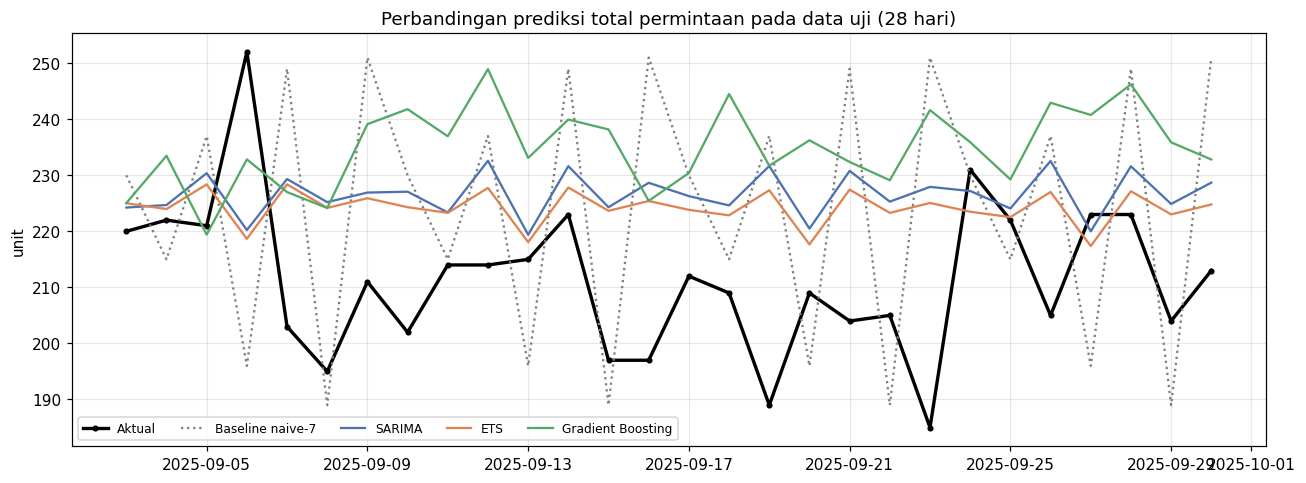

In [14]:
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(test.index, y_test.sum(axis=1), color="black", lw=2.2, marker="o", ms=3, label="Aktual")
ax.plot(test.index, forecast_baseline.sum(axis=1), ls=":", color="gray", label="Baseline naive-7")
ax.plot(test.index, forecast_sarima.sum(axis=1), color="#4c72b0", label="SARIMA")
ax.plot(test.index, forecast_ets.sum(axis=1), color="#dd8452", label="ETS")
ax.plot(test.index, forecast_gbr.sum(axis=1), color="#55a868", label="Gradient Boosting")
ax.set_title("Perbandingan prediksi total permintaan pada data uji (28 hari)")
ax.set_ylabel("unit")
ax.legend(ncol=5, fontsize=8)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "fig_2_test_zoom.png", dpi=120)
plt.show()

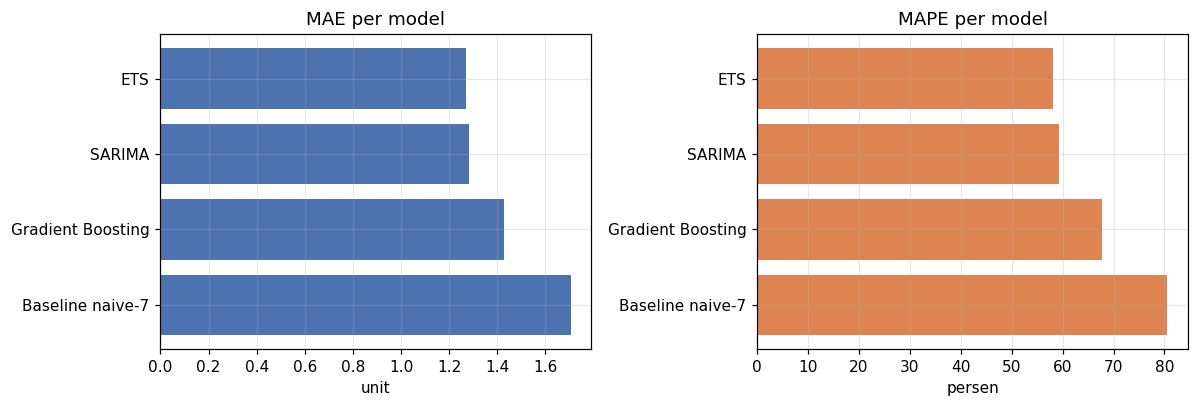

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))

axes[0].barh(summary.index, summary["MAE"], color="#4c72b0")
axes[0].set_title("MAE per model")
axes[0].set_xlabel("unit")
axes[0].invert_yaxis()

axes[1].barh(summary.index, summary["MAPE_%"], color="#dd8452")
axes[1].set_title("MAPE per model")
axes[1].set_xlabel("persen")
axes[1].invert_yaxis()

fig.tight_layout()
fig.savefig(OUTPUT_DIR / "fig_3_metrics.png", dpi=120)
plt.show()

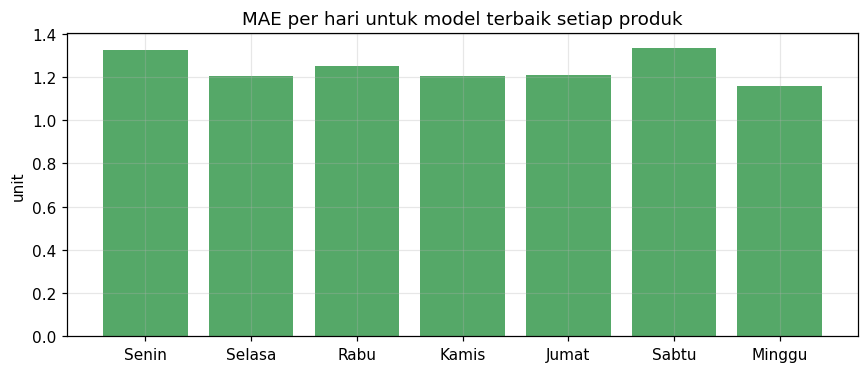

Senin     1.324
Selasa    1.204
Rabu      1.251
Kamis     1.207
Jumat     1.209
Sabtu     1.337
Minggu    1.159


In [16]:
best_forecast = np.column_stack([
    forecast_lookup[best_table.set_index("product").loc[product, "model"]][:, position]
    for position, product in enumerate(daily.columns)
])
error_frame = pd.DataFrame({
    "dow": test.index.dayofweek,
    "abs_error": np.abs(y_test - best_forecast).mean(axis=1),
})
error_by_dow = error_frame.groupby("dow").abs_error.mean()
error_by_dow.index = ["Senin", "Selasa", "Rabu", "Kamis", "Jumat", "Sabtu", "Minggu"]

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(error_by_dow.index, error_by_dow.values, color="#55a868")
ax.set_title("MAE per hari untuk model terbaik setiap produk")
ax.set_ylabel("unit")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "fig_4_error_dow.png", dpi=120)
plt.show()

print(error_by_dow.round(3).to_string())

## 9. Ekspor model terbaik ke pickle

Hanya **satu** model per produk yang disimpan: model terbaik dari tabel di atas, dilatih ulang memakai
**seluruh 272 hari**. Setiap model meramal **1 minggu (7 hari)** ke depan.

In [17]:
full_y = daily.to_numpy(dtype=float)

sarima_full = {}
for product in daily.columns:
    first = best_orders.loc[product]
    sarima_full[product] = SARIMAX(
        daily[product].to_numpy(dtype=float),
        order=(int(first.p), 1, int(first.q)),
        seasonal_order=(int(first.P), 1, int(first.Q), SEASON_LENGTH),
        enforce_stationarity=False,
        enforce_invertibility=False,
    ).fit(disp=False)

ets_full = {}
for product in daily.columns:
    ets_full[product] = ETSModel(
        daily[product].to_numpy(dtype=float),
        error="add",
        trend="add",
        damped_trend=True,
        seasonal="add",
        seasonal_periods=SEASON_LENGTH,
    ).fit(disp=False)

full_rows = {}
full_targets = {}
for product in daily.columns:
    y = daily[product].to_numpy(dtype=float)
    rows = []
    target = []
    for position in range(max(LAGS), len(y)):
        row = [y[position - lag] for lag in LAGS]
        row.append(np.mean(y[position - 7:position]))
        row.append(np.mean(y[position - 14:position]))
        row.append(np.mean(y[position - 28:position]))
        row.append(np.std(y[position - 7:position], ddof=1))
        date = daily.index[position]
        row.extend([date.dayofweek, int(date.dayofweek >= 5), date.day, date.month, date.dayofyear])
        rows.append(row)
        target.append(y[position])
    full_rows[product] = pd.DataFrame(rows, columns=FEATURE_NAMES)
    full_targets[product] = np.array(target, dtype=float)

gbr_full = {}
for product in daily.columns:
    gbr_full[product] = GradientBoostingRegressor(
        n_estimators=400,
        learning_rate=0.05,
        max_depth=3,
        subsample=0.9,
        random_state=SEED,
    )
    gbr_full[product].fit(full_rows[product], full_targets[product])

print(f"ketiga model dilatih ulang pada seluruh {len(full_y)} hari untuk {len(daily.columns)} produk")

C:\Users\Radit\anaconda3\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


C:\Users\Radit\anaconda3\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


ketiga model dilatih ulang pada seluruh 272 hari untuk 94 produk


In [18]:
# hanya model terbaik setiap produk yang dibungkus untuk disimpan
metric_lookup = metrics.set_index(["product", "model"]).MAE
best_bundles = {}

for product in daily.columns:
    best_name = best_table.set_index("product").loc[product, "model"]
    first = best_orders.loc[product]
    best_sarima = sarima_full[product]

    candidates = {
        # parameter SARIMA disimpan, objek hasil dibangun ulang saat berkas dimuat
        "SARIMA": {
            "params": best_sarima.params,
            "history": daily[product].to_numpy(dtype=float).tolist(),
            "freq": "D",
            "order": (int(first.p), 1, int(first.q)),
            "seasonal_order": (int(first.P), 1, int(first.Q), SEASON_LENGTH),
            "horizon_days": HORIZON_DAYS,
            "last_date": daily.index.max(),
            "mae_test": float(metric_lookup.loc[(product, "SARIMA")]),
        },
        "ETS": {
            "model": ets_full[product],
            "freq": "D",
            "seasonal_periods": SEASON_LENGTH,
            "horizon_days": HORIZON_DAYS,
            "last_date": daily.index.max(),
            "mae_test": float(metric_lookup.loc[(product, "ETS")]),
        },
        "Gradient Boosting": {
            "model": gbr_full[product],
            "freq": "D",
            "lags": LAGS,
            "feature_names": FEATURE_NAMES,
            "history": daily[product].to_numpy(dtype=float).tolist(),
            "horizon_days": HORIZON_DAYS,
            "last_date": daily.index.max(),
            "mae_test": float(metric_lookup.loc[(product, "Gradient Boosting")]),
        },
    }

    best_bundles[product] = dict(candidates[best_name], name=best_name, product=product)

with open(MODEL_PATH, "wb") as file:
    pickle.dump(best_bundles, file, protocol=pickle.HIGHEST_PROTOCOL)

print(f"produk disimpan    : {len(best_bundles)}")
print(f"sebaran algoritma  : {pd.Series([bundle['name'] for bundle in best_bundles.values()]).value_counts().to_dict()}")
print(f"cakupan prediksi   : {HORIZON_DAYS} hari (1 minggu) ke depan")
print(f"lokasi berkas      : {MODEL_PATH}")
print(f"ukuran berkas      : {MODEL_PATH.stat().st_size / 1024:,.1f} KB")

produk disimpan    : 94
sebaran algoritma  : {'ETS': 51, 'SARIMA': 29, 'Gradient Boosting': 14}
cakupan prediksi   : 7 hari (1 minggu) ke depan
lokasi berkas      : ..\artifacts\demand_forecast_product\model.pkl
ukuran berkas      : 10,044.3 KB


## 10. Menyimpan metadata

`metadata.json` mencatat asal data, rentang waktu, konfigurasi tiap model, hasil evaluasi, dan siapa model terbaik.
Berkas ini disimpan di folder yang sama dengan `model.pkl` agar satu paket bisa dipindah tanpa kehilangan konteks.

In [19]:
metadata = {
    "project": "MyVentory demand forecasting per produk",
    "target": "jumlah unit terjual per produk",
    "granularity": "harian per produk",
    "source": {
        "file": "data/Transactions.csv",
        "outlets": sorted(transactions.Outlet.unique().tolist()),
        "rows": int(len(transactions)),
        "products": int(daily.shape[1]),
    },
    "period": {
        "start": str(daily.index.min().date()),
        "end": str(daily.index.max().date()),
        "days": int(len(daily)),
    },
    "split": {
        "train_days": int(len(train)),
        "test_days": int(len(test)),
        "test_start": str(test.index.min().date()),
        "test_end": str(test.index.max().date()),
    },
    "seasonality": {
        "season_length_days": SEASON_LENGTH,
        "stl_strength": round(float(strength), 4),
    },
    "baseline": {
        "name": "seasonal naive-7",
        "mae": float(summary.loc["Baseline naive-7", "MAE"]),
    },
    "models": {
        record["model"]: {
            "MAE": round(float(record["MAE"]), 2),
            "RMSE": round(float(record["RMSE"]), 2),
            "MAPE_%": round(float(record["MAPE_%"]), 2),
            "sMAPE_%": round(float(record["sMAPE_%"]), 2),
            "bias": round(float(record["bias"]), 2),
        }
        for record in summary.reset_index().to_dict(orient="records")
    },
    "config": {
        "SARIMA": {"order": "grid AIC per produk", "seasonal_order": f"(P, 1, Q, {SEASON_LENGTH})"},
        "ETS": {"trend": "add damped", "seasonal": "add", "seasonal_periods": SEASON_LENGTH},
        "Gradient Boosting": {
            "n_estimators": 400,
            "learning_rate": 0.05,
            "max_depth": 3,
            "subsample": 0.9,
            "random_state": SEED,
            "features": FEATURE_NAMES,
        },
    },
    "saved_model": {
        "file": MODEL_PATH.name,
        "algorithm": "model terbaik per produk",
        "products": int(len(best_bundles)),
        "trained_on_days": int(len(full_y)),
        "last_date": str(daily.index.max().date()),
        "horizon_days": HORIZON_DAYS,
        "mae_test": round(float(best_table.MAE.mean()), 2),
    },
    "artifacts": [
        MODEL_PATH.name,
        METADATA_PATH.name,
        "demand_forecast_daily.csv",
        "demand_forecast_metrics.csv",
        "fig_1_series.png",
        "fig_2_test_zoom.png",
        "fig_3_metrics.png",
        "fig_4_error_dow.png",
    ],
}

METADATA_PATH.write_text(json.dumps(metadata, indent=2, ensure_ascii=False) + "\n", encoding="utf-8")
print("metadata tersimpan:", METADATA_PATH)
print(json.dumps(metadata["saved_model"], indent=2, ensure_ascii=False))

metadata tersimpan: ..\artifacts\demand_forecast_product\metadata.json
{
  "file": "model.pkl",
  "algorithm": "model terbaik per produk",
  "products": 94,
  "trained_on_days": 272,
  "last_date": "2025-09-30",
  "horizon_days": 7,
  "mae_test": 1.24
}


## 11. Menyimpan tabel prediksi dan metrik

Untuk lampiran laporan: nilai aktual, prediksi setiap model per produk, dan rekap metrik. Semua di folder yang sama.

In [20]:
forecast_table = pd.concat(
    [
        pd.DataFrame(
            {
                "tanggal": test.index,
                "product": product,
                "aktual": y_test[:, position],
                "baseline_naive7": forecast_baseline[:, position],
                "sarima": forecast_sarima.iloc[:, position].to_numpy(),
                "ets": forecast_ets.iloc[:, position].to_numpy(),
                "gradient_boosting": forecast_gbr.iloc[:, position].to_numpy(),
            }
        )
        for position, product in enumerate(daily.columns)
    ],
    ignore_index=True,
)
forecast_table.to_csv(OUTPUT_DIR / "demand_forecast_daily.csv", index=False)
metrics.to_csv(OUTPUT_DIR / "demand_forecast_metrics.csv", index=False)

print(f"isi folder {OUTPUT_DIR.resolve()}:")
for path in sorted(OUTPUT_DIR.iterdir()):
    print(f"  {path.name:<32} {path.stat().st_size / 1024:>9.1f} KB")

isi folder C:\Users\Radit\Politeknik Negeri Malang\Semester 5\ProjectBasedLearning_MyVentory\ML\artifacts\demand_forecast_product:
  demand_forecast_daily.csv            240.6 KB
  demand_forecast_metrics.csv           45.1 KB
  fig_1_series.png                     122.2 KB
  fig_2_test_zoom.png                  158.9 KB
  fig_3_metrics.png                     21.3 KB
  fig_4_error_dow.png                   19.0 KB
  metadata.json                          2.4 KB
  model.pkl                          10044.3 KB


## 12. Verifikasi berkas pickle

Berkas dimuat ulang dari disk tanpa memakai variabel notebook, lalu dipakai meramal 7 hari setelah 30 September 2025.
Kalau cell ini berhasil, model bisa dipakai di sistem lain hanya dengan folder ini.

In [21]:
next_dates = pd.date_range(daily.index.max() + pd.Timedelta(days=1), periods=HORIZON_DAYS, freq="D")

with open(MODEL_PATH, "rb") as file:
    loaded = pickle.load(file)

predictions = {}
for product, bundle in loaded.items():
    if "lags" in bundle:
        loaded_model = bundle["model"]
        history = list(bundle["history"])
        values = []
        for date in next_dates:
            row = [history[-lag] for lag in bundle["lags"]]
            row.append(np.mean(history[-7:]))
            row.append(np.mean(history[-14:]))
            row.append(np.mean(history[-28:]))
            row.append(np.std(history[-7:], ddof=1))
            row.extend([date.dayofweek, int(date.dayofweek >= 5), date.day, date.month, date.dayofyear])
            value = max(0.0, float(loaded_model.predict(pd.DataFrame([row], columns=bundle["feature_names"]))[0]))
            values.append(value)
            history.append(value)
    elif "params" in bundle:
        loaded_model = SARIMAX(
            bundle["history"],
            order=tuple(bundle["order"]),
            seasonal_order=tuple(bundle["seasonal_order"]),
            enforce_stationarity=False,
            enforce_invertibility=False,
        ).smooth(bundle["params"])
        values = np.clip(np.asarray(loaded_model.forecast(HORIZON_DAYS), dtype=float), 0, None)
    else:
        loaded_model = bundle["model"]
        values = np.clip(np.asarray(loaded_model.forecast(HORIZON_DAYS), dtype=float), 0, None)

    predictions[product] = values

predictions = pd.DataFrame(predictions, index=next_dates)

print("berkas         :", MODEL_PATH.name)
print("jumlah produk  :", predictions.shape[1])
print("data terakhir  :", daily.index.max().date())
print("periode ramalan:", next_dates.min().date(), "s/d", next_dates.max().date())
print()
print("total prediksi per hari (unit):")
print(predictions.sum(axis=1).round(1).to_string())
print()
print("lima produk dengan prediksi terbesar (total 7 hari):")
print(predictions[predictions.sum().sort_values(ascending=False).head(5).index].round(2).to_string())

berkas         : model.pkl
jumlah produk  : 94
data terakhir  : 2025-09-30
periode ramalan: 2025-10-01 s/d 2025-10-07

total prediksi per hari (unit):
2025-10-01    221.2
2025-10-02    218.5
2025-10-03    222.3
2025-10-04    212.5
2025-10-05    222.3
2025-10-06    216.2
2025-10-07    212.0
Freq: D

lima produk dengan prediksi terbesar (total 7 hari):
            Apple Pie Latte (Gedhe)  Green Thai Tea (Gedhe)  Friendly Coffee (Hot)  Americano (Ice Arabica)  Happy Moca (Hot)
2025-10-01                     4.69                    2.75                   3.24                     2.00              2.37
2025-10-02                     5.18                    3.24                   3.40                     2.82              2.81
2025-10-03                     2.37                    2.29                   2.47                     3.22              2.84
2025-10-04                     2.22                    2.29                   2.39                     3.30              2.84
2025-10-05       

## 13. Ringkasan

In [22]:
print("RINGKASAN HASIL")
print("-" * 62)
print(f"target          : permintaan {daily.shape[1]} produk per hari")
print(f"periode data    : {daily.index.min().date()} s/d {daily.index.max().date()} ({len(daily)} hari)")
print(f"data uji        : {len(test)} hari")
print()
print(summary.round(2).to_string())
print()
print("model terbaik per produk:")
print(best_table.model.value_counts().to_string())
print()
print(f"MAE rata-rata   : {best_table.MAE.mean():.2f} unit per produk per hari")
print(f"MAPE rata-rata  : {best_table['MAPE_%'].mean():.2f}%")
print()
print("isi folder keluaran:")
for path in sorted(OUTPUT_DIR.iterdir()):
    print("  ", path.name)

RINGKASAN HASIL
--------------------------------------------------------------
target          : permintaan 94 produk per hari
periode data    : 2025-01-02 s/d 2025-09-30 (272 hari)
data uji        : 28 hari

                    MAE  RMSE  MAPE_%  sMAPE_%  bias
model                                               
ETS                1.27  1.56   58.16    63.44  0.14
SARIMA             1.28  1.58   59.32    63.72  0.16
Gradient Boosting  1.43  1.76   67.64    68.81  0.25
Baseline naive-7   1.71  2.16   80.59    83.52  0.13

model terbaik per produk:
model
ETS                  51
SARIMA               29
Gradient Boosting    14

MAE rata-rata   : 1.24 unit per produk per hari
MAPE rata-rata  : 55.84%

isi folder keluaran:
   demand_forecast_daily.csv
   demand_forecast_metrics.csv
   fig_1_series.png
   fig_2_test_zoom.png
   fig_3_metrics.png
   fig_4_error_dow.png
   metadata.json
   model.pkl


## Export model ke API (berversion)

Model disalin ke `API/artifacts/demand_forecast_product/1.0.0/` sehingga versi lama tetap tersimpan dan bisa
dibandingkan. Versi juga ditulis ke `metadata.json` sebagai `model_version`.

In [23]:
import shutil

NOTEBOOK_NAME = "demand_forecast_product"
NOTEBOOK_VERSION = "1.0.0"
API_DIR = Path("..").resolve().parent / "API" / "artifacts" / NOTEBOOK_NAME / NOTEBOOK_VERSION
API_DIR.mkdir(parents=True, exist_ok=True)

api_metadata = json.loads((OUTPUT_DIR / "metadata.json").read_text(encoding="utf-8"))
api_metadata.update({
    "model_id": NOTEBOOK_NAME,
    "model_version": NOTEBOOK_VERSION,
    "source_notebook": NOTEBOOK_NAME,
})

shutil.copy2(OUTPUT_DIR / "model.pkl", API_DIR / "model.pkl")
(API_DIR / "metadata.json").write_text(
    json.dumps(api_metadata, indent=2, ensure_ascii=False) + "\n",
    encoding="utf-8",
)

print(f"{NOTEBOOK_NAME} versi {NOTEBOOK_VERSION} diekspor ke:")
print(" ", API_DIR)
for path in sorted(API_DIR.iterdir()):
    print(f"   {path.name:<20} {path.stat().st_size / 1024:>9.1f} KB")

demand_forecast_product versi 1.0.0 diekspor ke:
  C:\Users\Radit\Politeknik Negeri Malang\Semester 5\ProjectBasedLearning_MyVentory\API\artifacts\demand_forecast_product\1.0.0
   metadata.json              2.6 KB
   model.pkl              10044.3 KB
